In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
support = pd.read_csv(
    "../../result/HEK293T_HCT116/coemb/promergeclub_HEK293Tanchor/HCT116/HCT116_support.tsv",
    sep="\t",
    index_col=0,
)
names = pd.Index(sorted(support.index[support["base"] == 1]))

In [3]:
# ProMERGE specific score
specific_score = {}
for anchor, query in [("HCT116", "HEK293T"), ("HEK293T", "HCT116")]:
    specific_score[query] = pd.read_csv(
        "../../result/HEK293T_HCT116/coemb/"
        f"promergeclub_{anchor}anchor/"
        f"{query}/{query}_specific_score.tsv",
        sep="\t",
        index_col=0,
    )["specific_score"].reindex(names)

In [4]:
def load_neighbours(modality, cell):
    """
    Partner set of every protein in the raw PPI list of one modality
    and one cell line.
    """
    frame = pd.read_csv(
        f"../../result/HEK293T_HCT116/input/{modality}-{cell}.ppi",
        sep="\t",
    )
    neighbours = {}
    for a, b in zip(frame["GeneA"], frame["GeneB"]):
        neighbours.setdefault(a, set()).add(b)
        neighbours.setdefault(b, set()).add(a)
    return neighbours


def raw_change(modality):
    """
    Per protein in both cell lines' networks of one modality: the
    absolute log2 degree ratio and the Jaccard distance of the
    partner sets, over the shared proteins.
    """
    nb_q = load_neighbours(modality, "HEK293T")
    nb_b = load_neighbours(modality, "HCT116")
    shared = set(nb_q) & set(nb_b)
    rows = []
    for gene in sorted(shared):
        sq = nb_q[gene] & shared
        sb = nb_b[gene] & shared
        union = len(sq | sb)
        rows.append({
            "gene": gene,
            "absdlogdeg": abs(np.log2((len(sq) + 1) / (len(sb) + 1))),
            "raw_jaccard": (1 - len(sq & sb) / union) if union else 0.0,
        })
    return pd.DataFrame(rows).set_index("gene")


# Raw PPI rewire baseline
raw = {m: raw_change(m) for m in ["BioPlex", "SECMX"]}
raw_pct = pd.DataFrame({
    signal: pd.concat(
        [raw[m][signal].reindex(names).rank(pct=True) for m in raw],
        axis=1,
    ).mean(axis=1)
    for signal in ["absdlogdeg", "raw_jaccard"]
})

In [5]:
def residualize(target, covariates):
    """
    OLS residual of target on covariates (with intercept).
    """
    out = pd.Series(np.nan, index=target.index)
    keep = target.notna() & covariates.notna().all(axis=1)
    design = np.column_stack(
        [np.ones(keep.sum()), covariates[keep].values]
    )
    beta = np.linalg.lstsq(design, target[keep].values, rcond=None)[0]
    out[keep] = target[keep].values - design @ beta
    return out


# ProMERGE effect: percentile of the specific score
# in each direction, averaged over both
effect = pd.DataFrame({
    query: specific_score[query].rank(pct=True) for query in specific_score
}).mean(axis=1)

# Score: the part of the ProMERGE effect not explained by the
# raw ppi rewire baseline, residualised over all proteins and re-percentiled
resid = residualize(effect, raw_pct)
score = resid.rank(pct=True)

In [6]:
ranking = pd.DataFrame({
    "gene": names,
    "score": score.values,
    "rank": score.rank(ascending=False, method="min").values,
}).dropna(subset=["score"]).sort_values("rank")
ranking["rank"] = ranking["rank"].astype(int)
ranking.to_csv("./fig3_ranking.tsv", sep="\t", index=False)

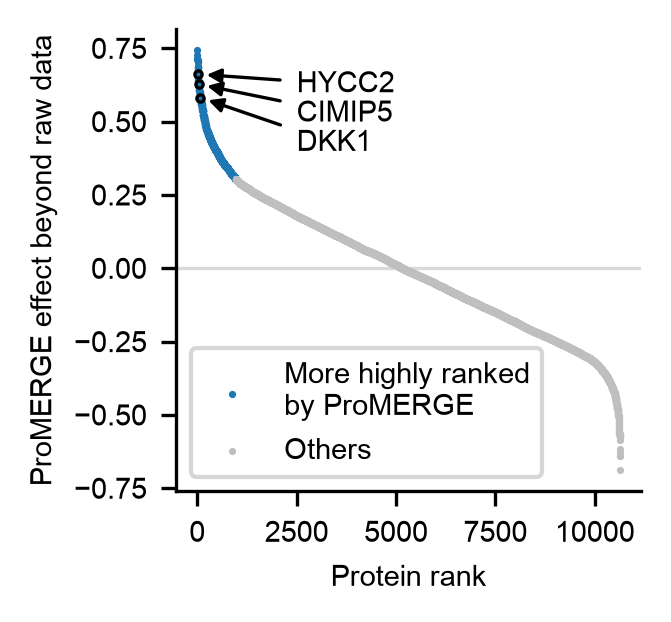

In [7]:
plt.style.use("/home/jig049/misc/style.mplstyle")

x = ranking["rank"].values
y = resid.loc[ranking["gene"]].values
chord = y[0] + (y[-1] - y[0]) * (x - x[0]) / (x[-1] - x[0])
knee = x[np.argmax(chord - y)]
blue = x < knee
hycc2 = ranking["gene"].values == "HYCC2"
dkk1 = ranking["gene"].values == "DKK1"
cimip5 = ranking["gene"].values == "CIMIP5"

fig, ax = plt.subplots(figsize=(2, 2), dpi=300)
ax.axhline(0, color="0.85", lw=0.8, zorder=0)
ax.scatter(
    x[blue],
    y[blue],
    s=3,
    color="#1f77b4",
    lw=0,
    label=f"More highly ranked\nby ProMERGE",
)

ax.scatter(
    x[~blue],
    y[~blue],
    s=3,
    color="0.75",
    lw=0,
    label="Others",
)

ax.scatter(
    x[hycc2],
    y[hycc2],
    s=3,
    color="#1f77b4",
    edgecolor="black",
    lw=0.8,
    zorder=3,
)
ax.annotate(
    "HYCC2",
    xy=(x[hycc2][0], y[hycc2][0]),
    xytext=(2500, 0.6),
    fontsize=7,
    arrowprops=dict(arrowstyle="-|>", color="black", lw=0.8),
)

ax.scatter(
    x[cimip5],
    y[cimip5],
    s=3,
    color="#1f77b4",
    edgecolor="black",
    lw=0.8,
    zorder=3,
)
ax.annotate(
    "CIMIP5",
    xy=(x[cimip5][0], y[cimip5][0]),
    xytext=(2500, 0.5),
    fontsize=7,
    arrowprops=dict(arrowstyle="-|>", color="black", lw=0.8),
)

ax.scatter(
    x[dkk1],
    y[dkk1],
    s=3,
    color="#1f77b4",
    edgecolor="black",
    lw=0.8,
    zorder=3,
)
ax.annotate(
    "DKK1",
    xy=(x[dkk1][0], y[dkk1][0]),
    xytext=(2500, 0.4),
    fontsize=7,
    arrowprops=dict(arrowstyle="-|>", color="black", lw=0.8),
)

ax.set_xlabel("Protein rank")
ax.set_ylabel("ProMERGE effect beyond raw data")
ax.legend(frameon=True, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)

fig.savefig("./fig3_ranking.pdf", bbox_inches="tight", transparent=True)